# Part 2 Wrap Up (Fall 2026) | Figures

Builds every `i/f26_*.png` used in `concept_wrapup_2_F26.qmd`.

- All data here is simulated with a fixed seed; nothing is read from `data/`.
- The small tables typed into the slides are entered below so their answers are checked here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 16,
    'axes.titlesize': 20,
    'axes.labelsize': 16,
    'font.style': 'italic',
    'figure.dpi': 400
})
rng = np.random.default_rng(150)
C0, C1, C2 = 'tab:blue', 'tab:orange', 'tab:green'

## Choose the visualization

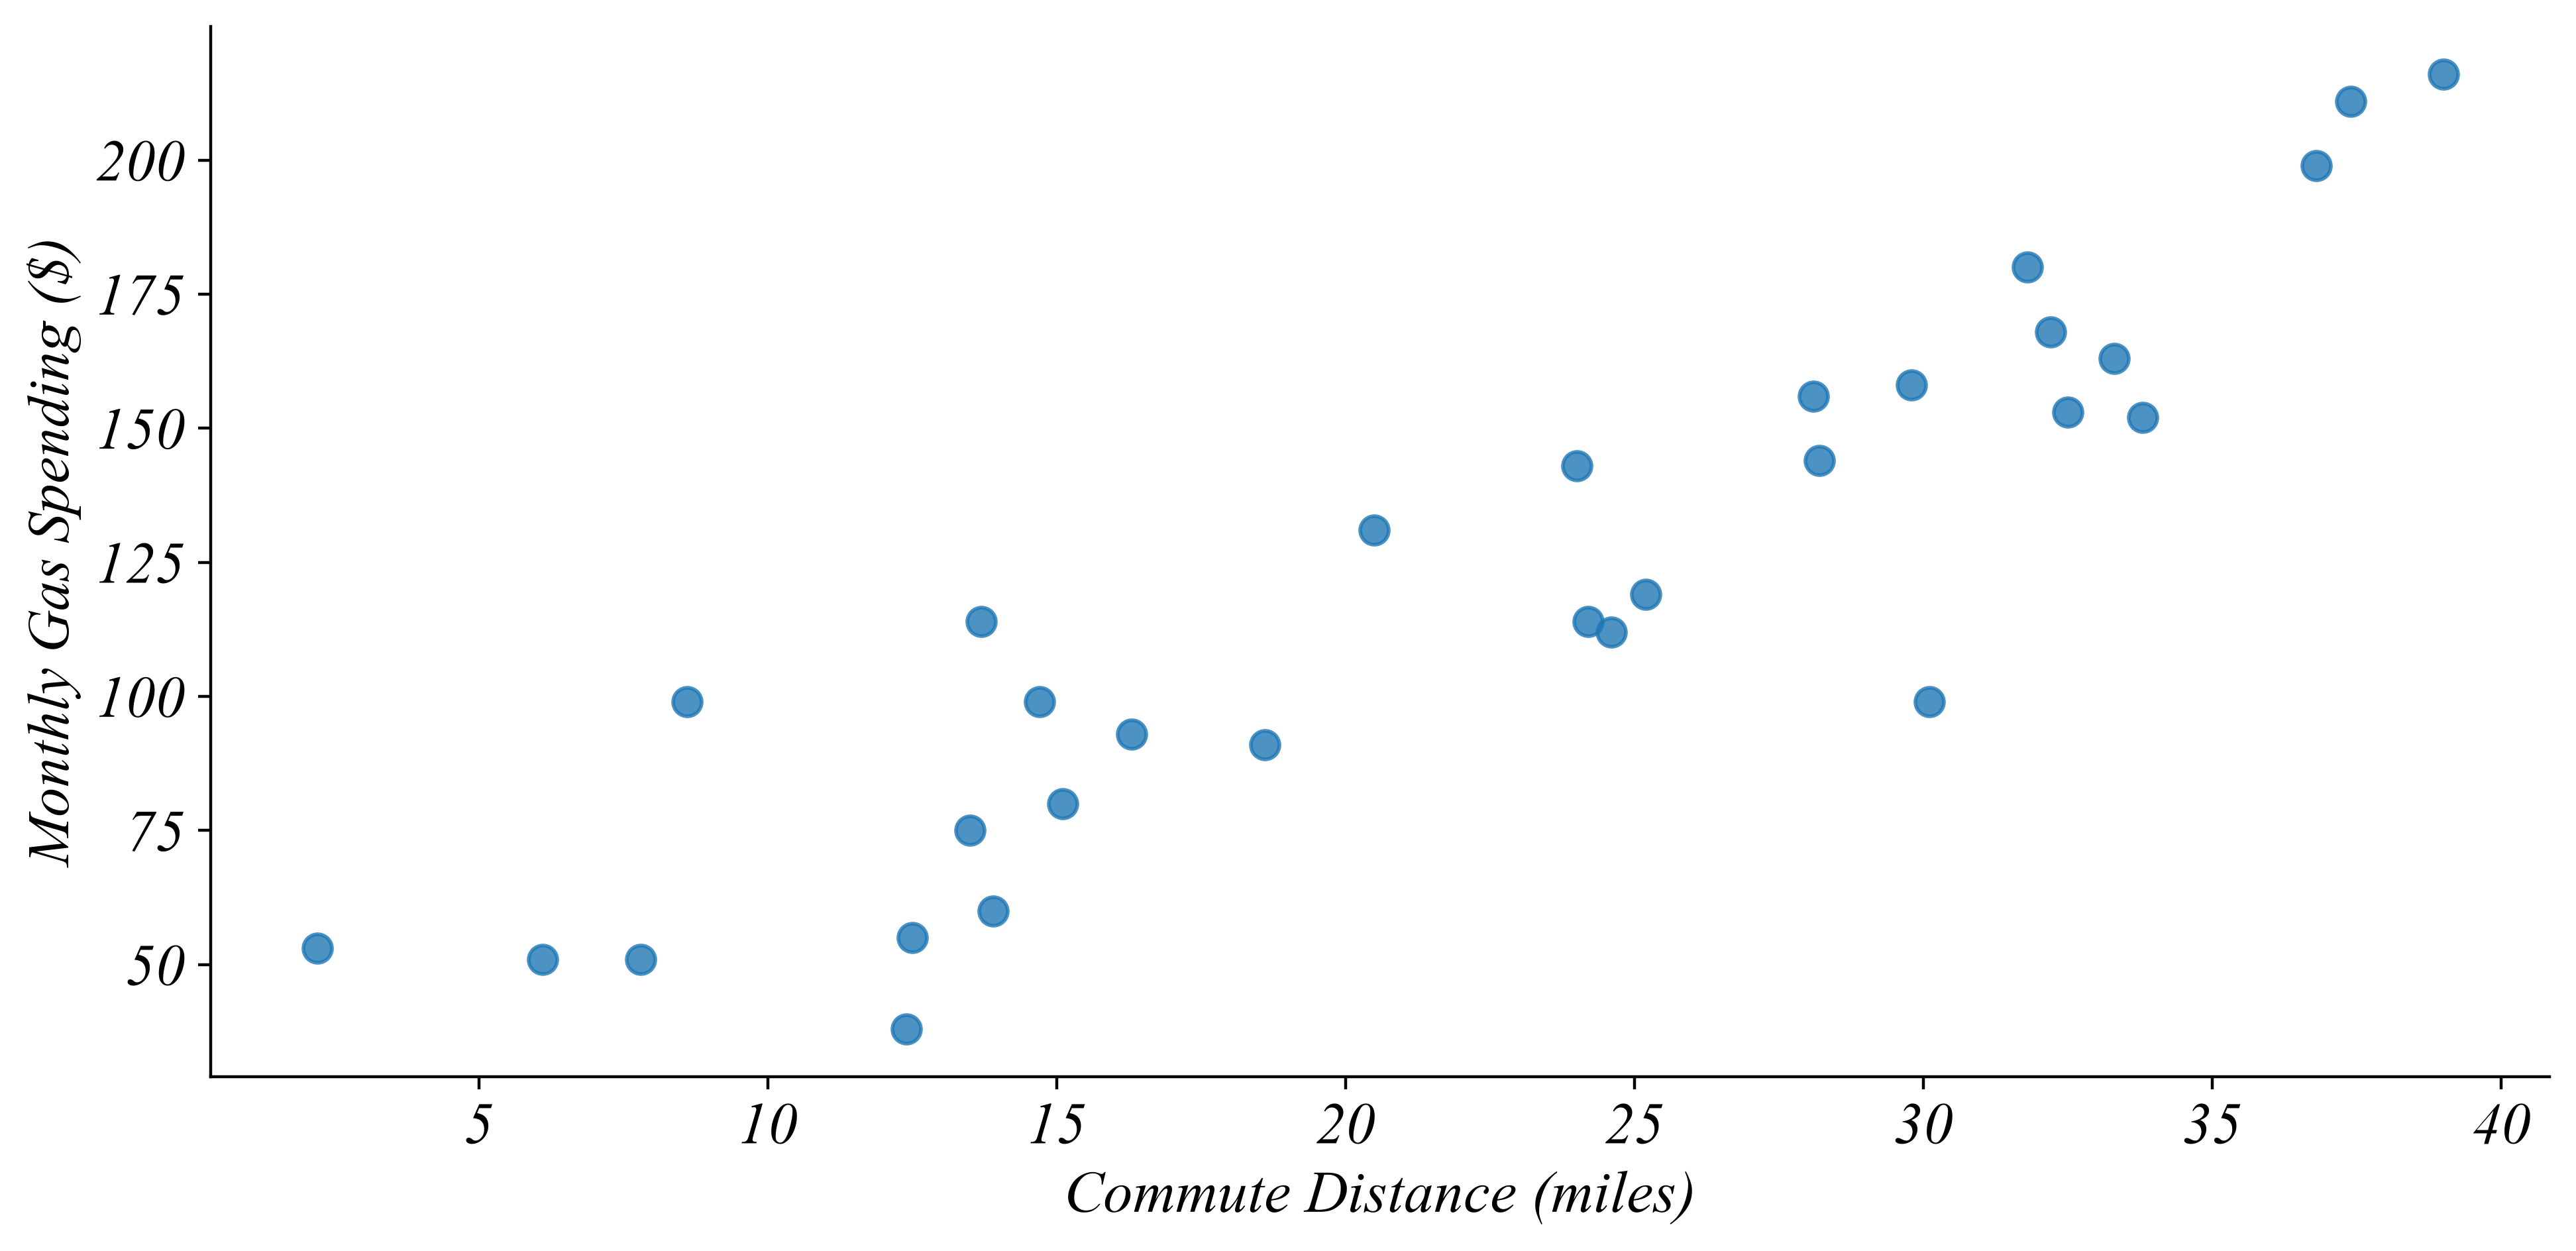

   Commute_Miles  Gas_Spend
0            2.2       53.0
1           37.4      211.0
2           31.8      180.0
3           14.7       99.0
4           28.1      156.0


In [2]:
# (a) Commute distance vs monthly gas spending: numerical by numerical
miles = rng.uniform(2, 40, 30).round(1)
gas = (20 + 4.5 * miles + rng.normal(0, 18, 30)).round(0)
commute = pd.DataFrame({'Commute_Miles': miles, 'Gas_Spend': gas})

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(commute['Commute_Miles'], commute['Gas_Spend'], s=60, alpha=0.8)
ax.set(xlabel='Commute Distance (miles)', ylabel='Monthly Gas Spending ($)')
sns.despine(); plt.tight_layout(); plt.savefig('i/f26_choose_a.png'); plt.show()
print(commute.head())

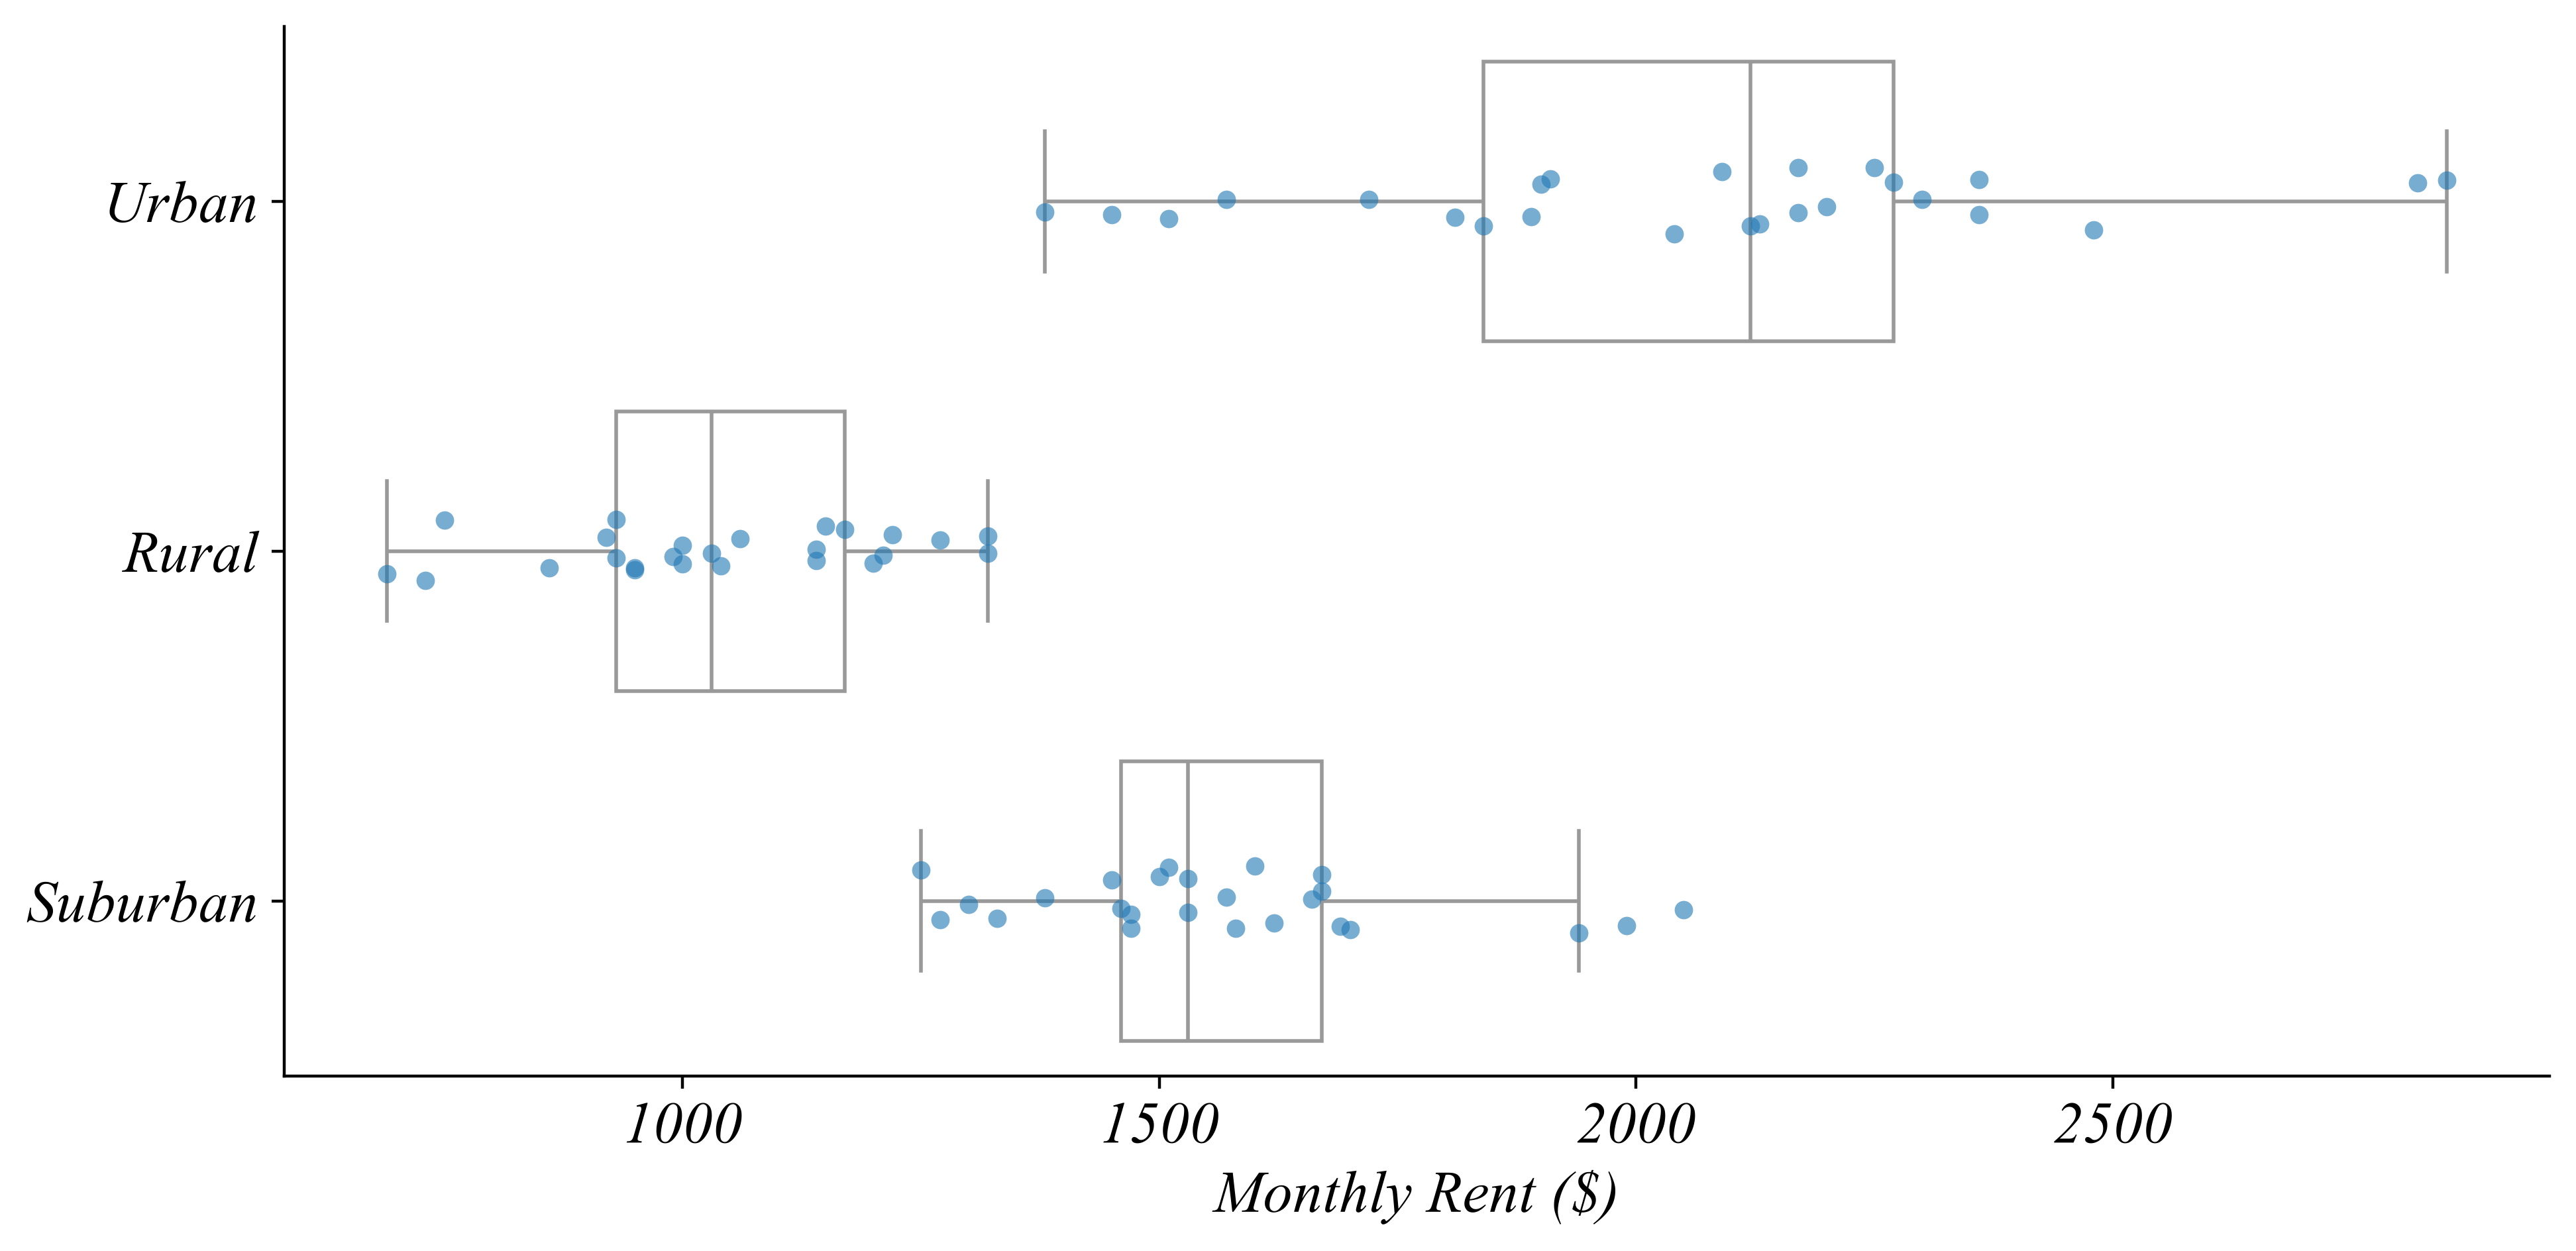

     Area    Rent
19  Urban  2130.0
5   Rural  1060.0
10  Urban  1720.0
20  Rural   860.0
4   Rural   950.0


In [3]:
# (b) Rent by area type: numerical by categorical
areas = {'Urban': (2100, 350), 'Suburban': (1600, 250), 'Rural': (1100, 200)}
rent = pd.concat([pd.DataFrame({'Area': a, 'Rent': rng.normal(m, s, 25).round(-1)})
                  for a, (m, s) in areas.items()]).sample(frac=1, random_state=1)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=rent, x='Rent', y='Area', color='white', showfliers=False, ax=ax)
sns.stripplot(data=rent, x='Rent', y='Area', alpha=0.6, ax=ax)
ax.set(xlabel='Monthly Rent ($)', ylabel='')
sns.despine(); plt.tight_layout(); plt.savefig('i/f26_choose_b.png'); plt.show()
print(rent.head())

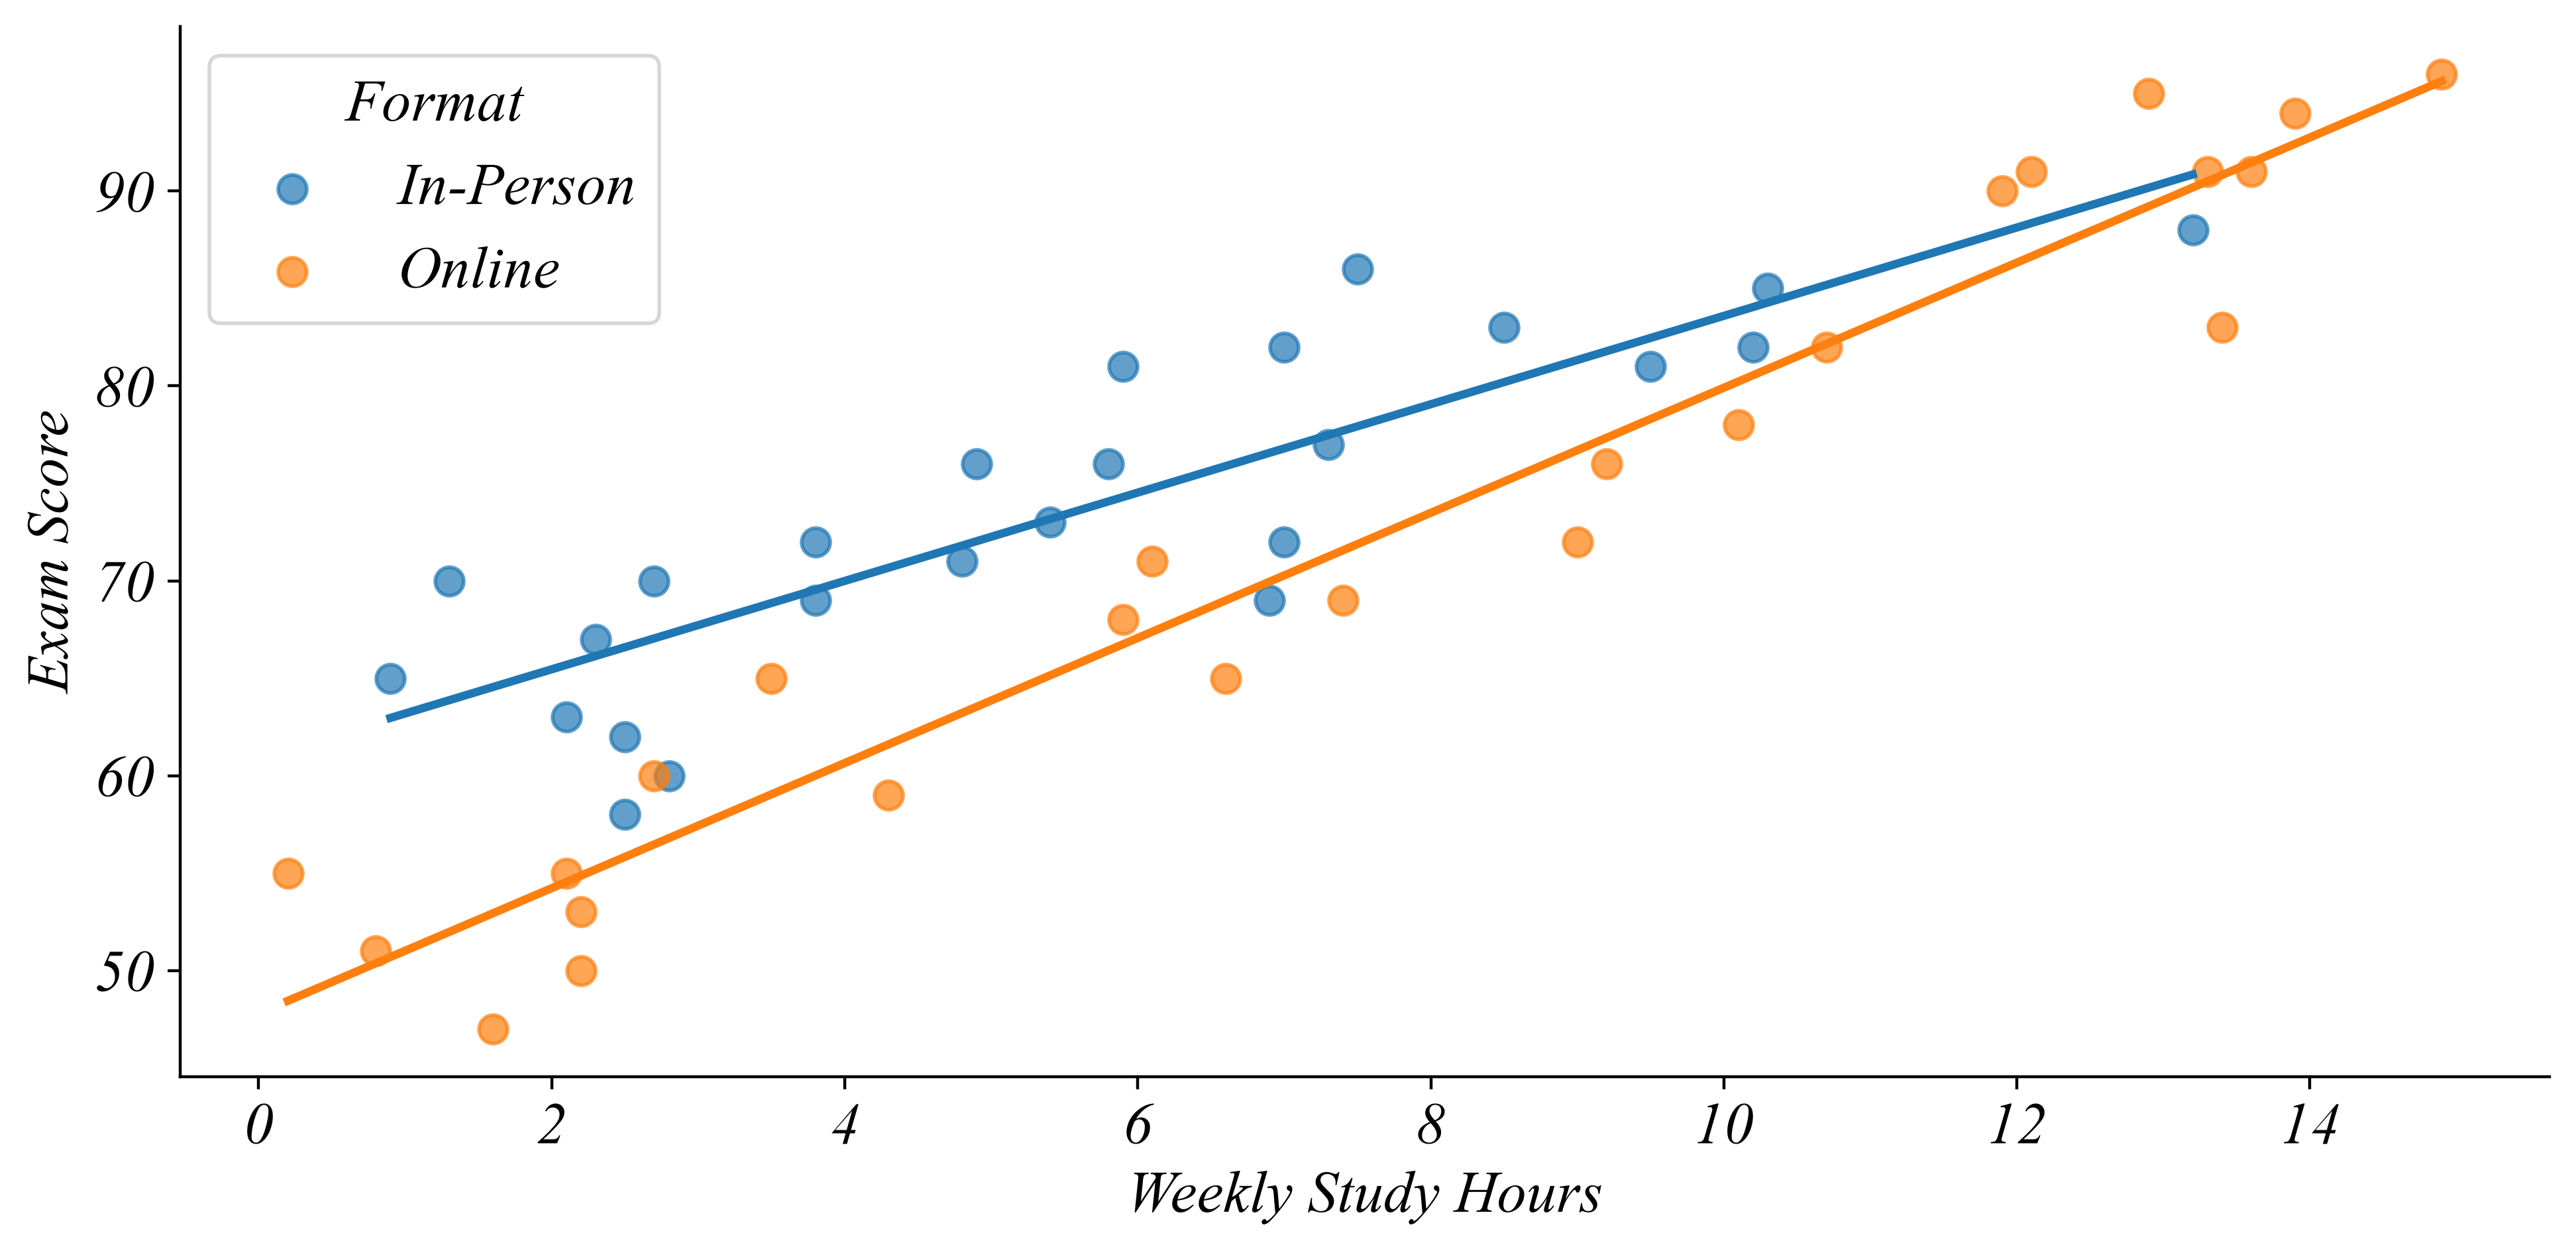

       Format  Study_Hours  Exam_Score
11     Online          3.5        65.0
22     Online         13.4        83.0
3      Online          0.8        51.0
9   In-Person          0.9        65.0
13  In-Person          1.3        70.0


In [4]:
# (c) Study hours vs exam score by course format: numerical by numerical by categorical
frames = []
for fmt, (b0, b1) in {'In-Person': (62, 2.0), 'Online': (48, 3.2)}.items():
    h = rng.uniform(0, 15, 25).round(1)
    frames.append(pd.DataFrame({'Format': fmt, 'Study_Hours': h,
                                'Exam_Score': (b0 + b1 * h + rng.normal(0, 5, 25)).clip(0, 100).round(0)}))
study = pd.concat(frames).sample(frac=1, random_state=2)

fig, ax = plt.subplots(figsize=(10, 5))
for fmt, c in zip(['In-Person', 'Online'], [C0, C1]):
    sns.regplot(data=study[study['Format'] == fmt], x='Study_Hours', y='Exam_Score',
                ci=None, color=c, label=fmt, scatter_kws={'s': 60, 'alpha': 0.7}, ax=ax)
ax.set(xlabel='Weekly Study Hours', ylabel='Exam Score')
ax.legend(title='Format'); sns.despine(); plt.tight_layout(); plt.savefig('i/f26_choose_c.png'); plt.show()
print(study.head())

## Ask a specific question

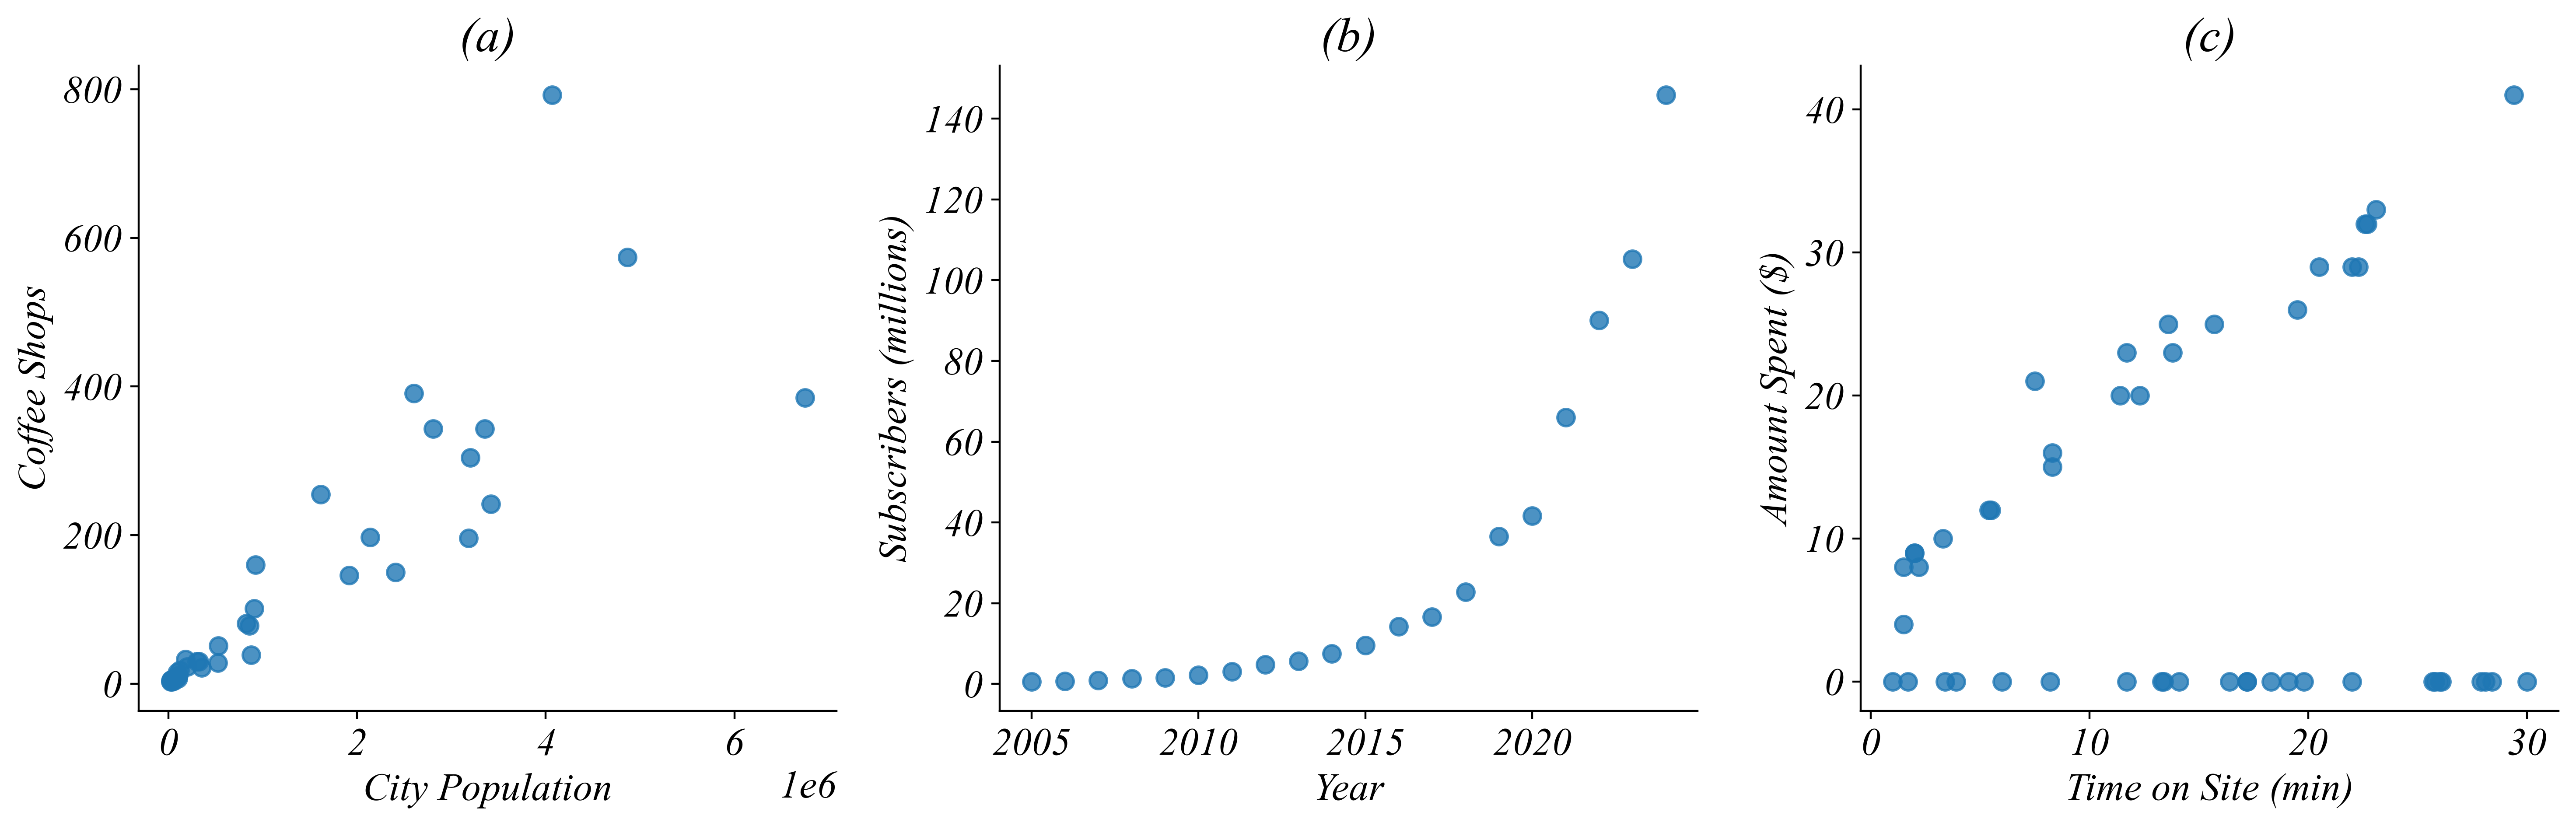

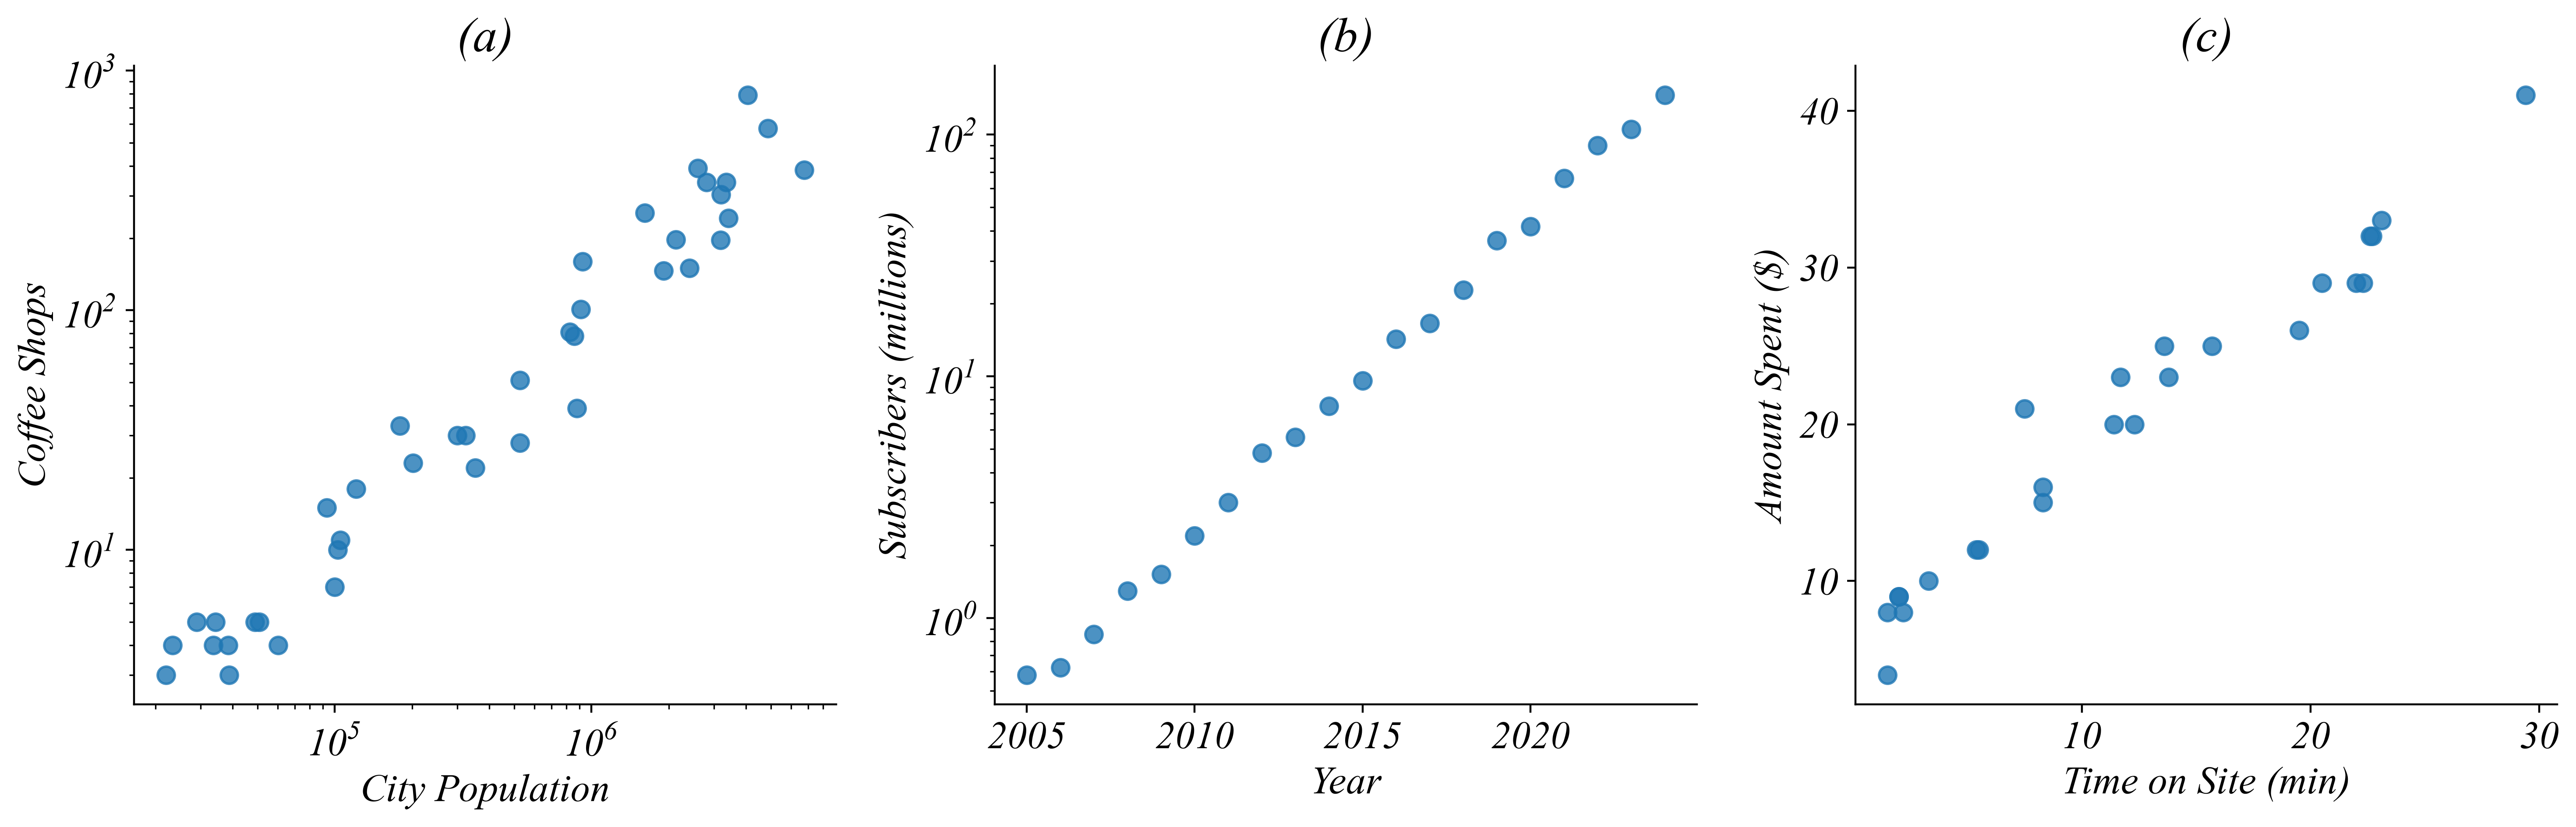

In [5]:
# (a) both variables right-skewed, (b) steady percentage growth, (c) most visitors buy nothing
pop = np.exp(rng.uniform(np.log(2e4), np.log(1e7), 40))
shops = (pop / 1e4 * np.exp(rng.normal(0, 0.4, 40))).round(0) + 1
years = np.arange(2005, 2025)
subs = 0.5 * 1.35 ** (years - 2005) * np.exp(rng.normal(0, 0.08, len(years)))
minutes = rng.uniform(1, 30, 50).round(1)
buys = rng.random(50) < 0.4
spend = np.where(buys, (5 + 1.2 * minutes + rng.normal(0, 3, 50)).round(0), 0)

def panels(fixed):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    ax = axes[0]
    ax.scatter(pop, shops, s=50, alpha=0.8)
    ax.set(xlabel='City Population', ylabel='Coffee Shops', title='(a)')
    if fixed: ax.set(xscale='log', yscale='log')
    ax = axes[1]
    ax.scatter(years, subs, s=50, alpha=0.8)
    ax.set(xlabel='Year', ylabel='Subscribers (millions)', title='(b)')
    if fixed: ax.set_yscale('log')
    ax = axes[2]
    keep = spend > 0 if fixed else np.full(50, True)
    ax.scatter(minutes[keep], spend[keep], s=50, alpha=0.8)
    ax.set(xlabel='Time on Site (min)', ylabel='Amount Spent ($)', title='(c)')
    sns.despine(); plt.tight_layout()
    return fig

panels(False).savefig('i/f26_fix_raw.png'); plt.show()
panels(True).savefig('i/f26_fix_fixed.png'); plt.show()

## Investigate before you visualize

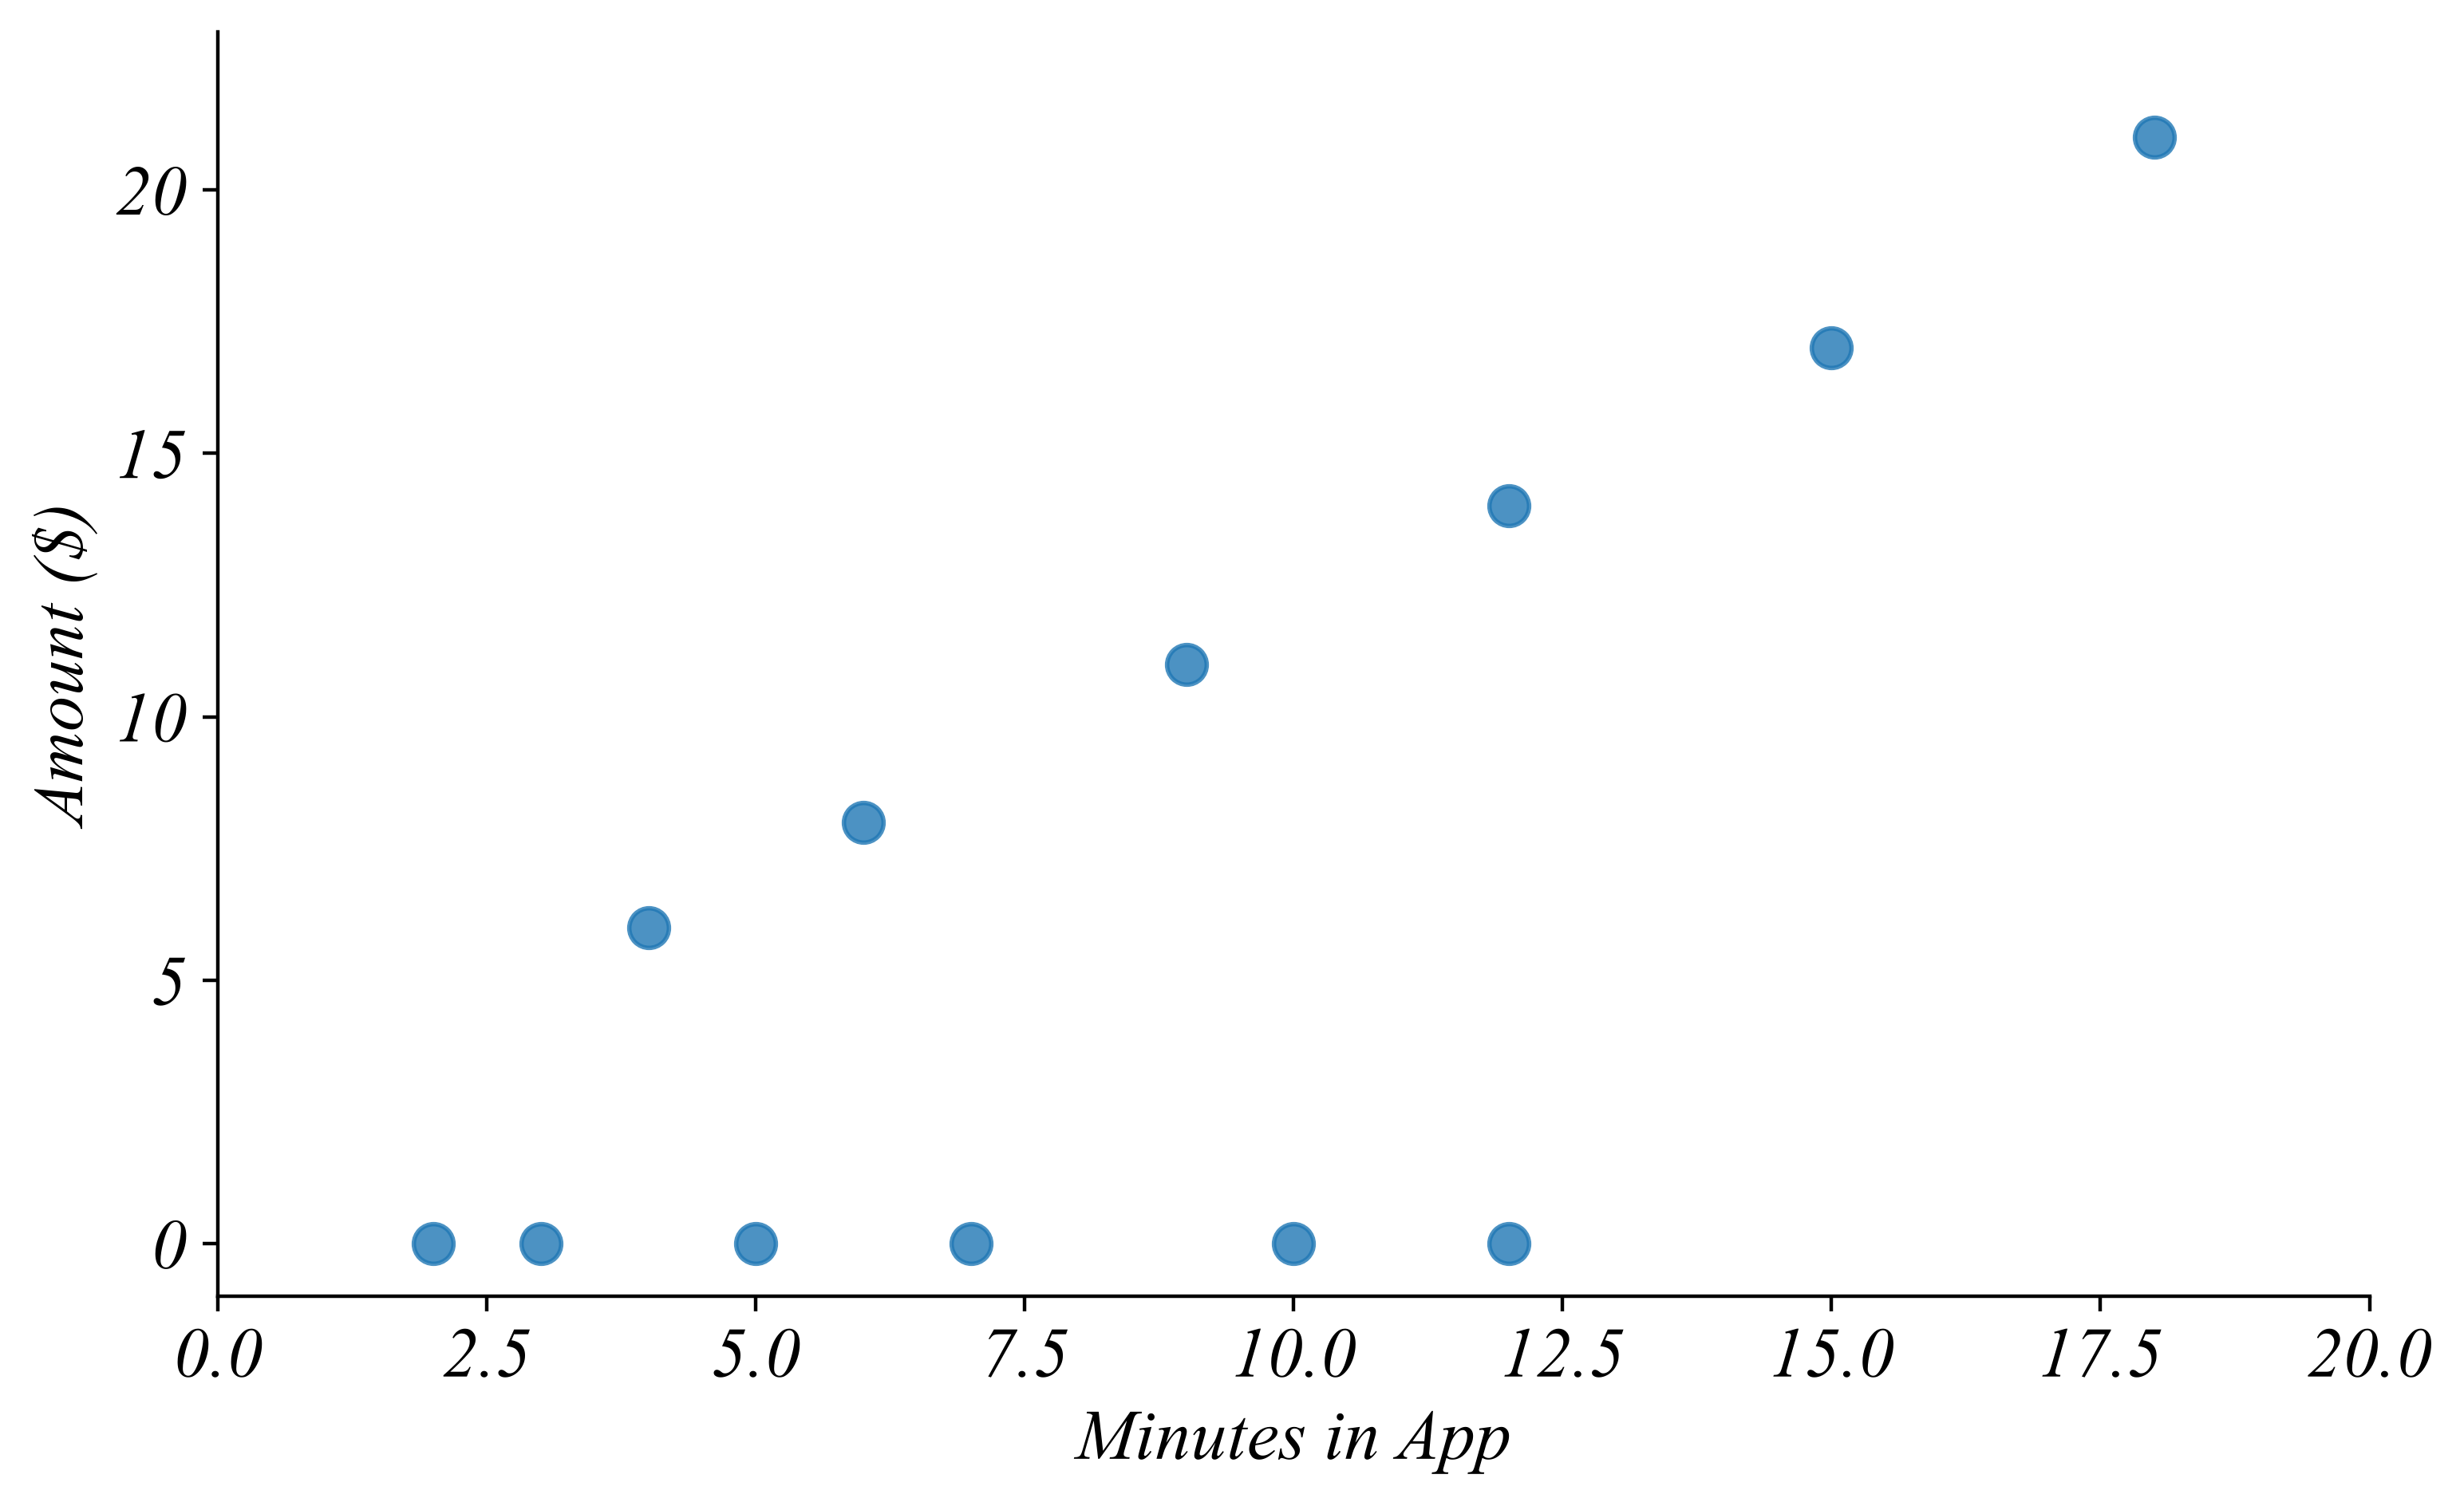

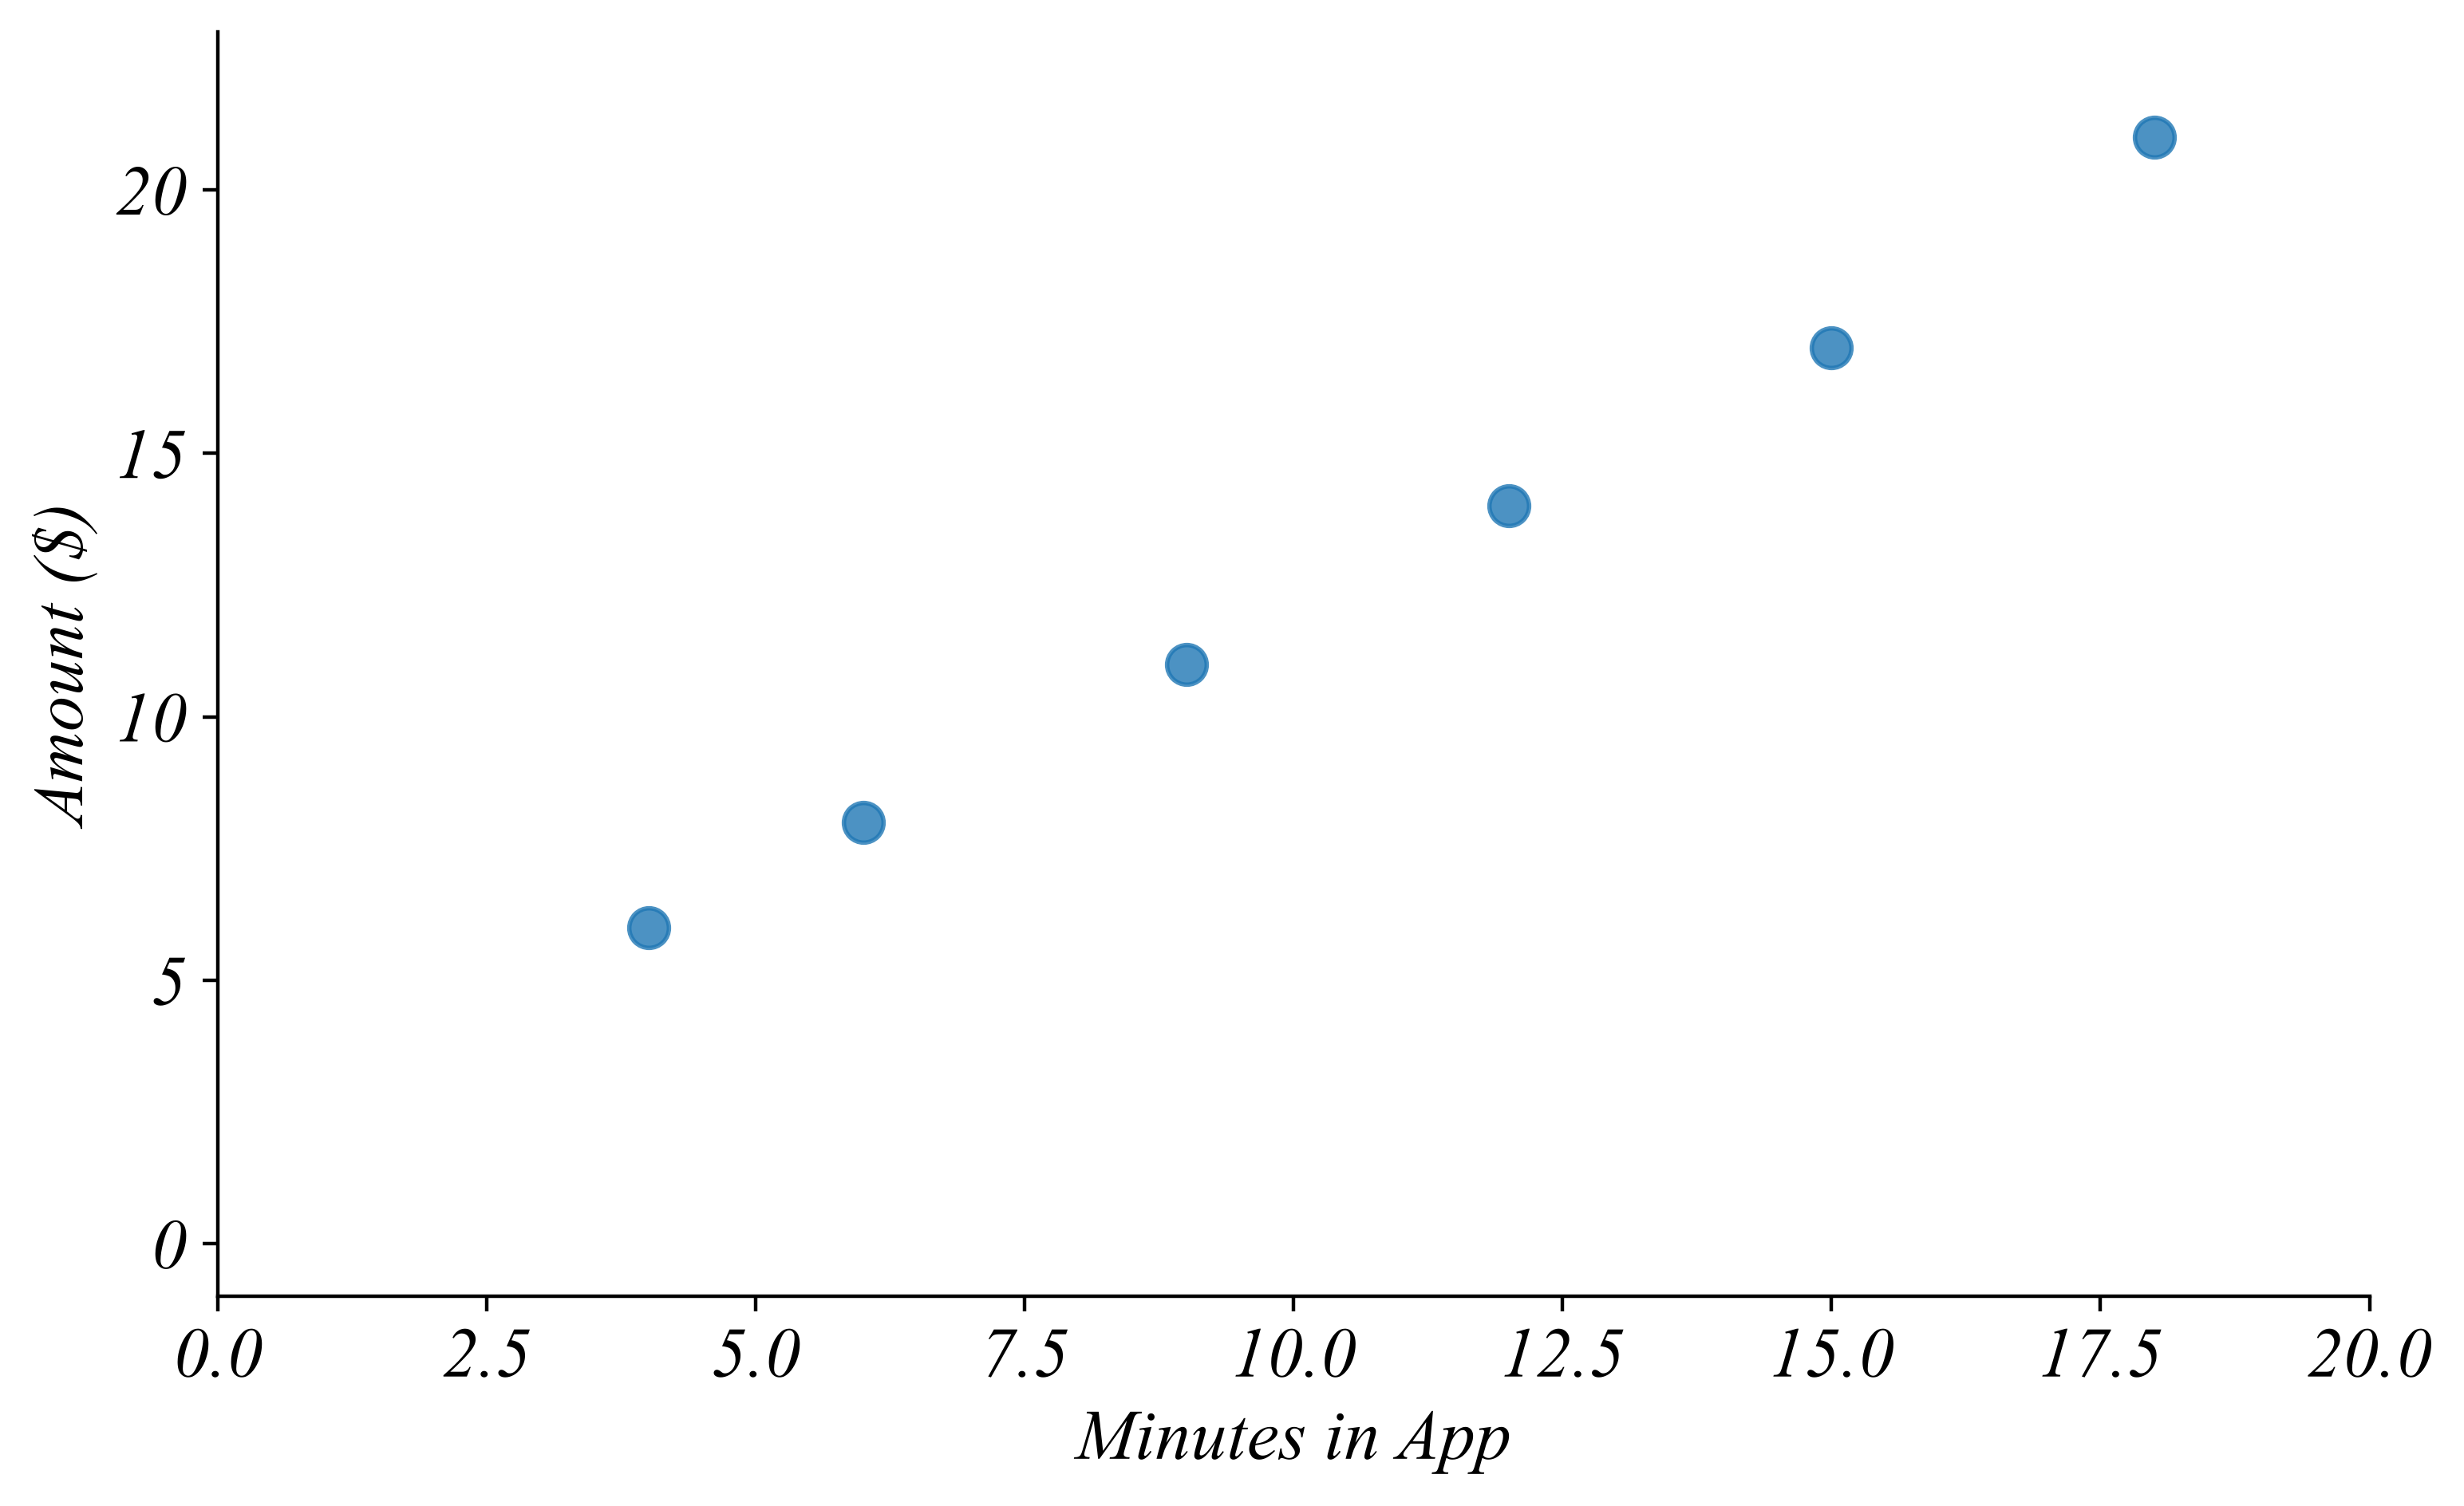

In [6]:
# Typed into the slide as a table
app = pd.DataFrame({
    'Session': [f'S{i:02d}' for i in range(1, 13)],
    'Event': ['Purchased', 'Browsed'] * 6,
    'Minutes': [4, 2, 9, 7, 15, 12, 6, 3, 12, 10, 18, 5],
    'Amount': [6, 0, 11, 0, 17, 0, 8, 0, 14, 0, 21, 0]})

for name, d in [('all', app), ('filtered', app[app['Event'] == 'Purchased'])]:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(d['Minutes'], d['Amount'], s=80, alpha=0.8)
    ax.set(xlabel='Minutes in App', ylabel='Amount ($)', xlim=(0, 20), ylim=(-1, 23))
    sns.despine(); plt.tight_layout(); plt.savefig(f'i/f26_investigate_{name}.png'); plt.show()

## Read a scatter by category

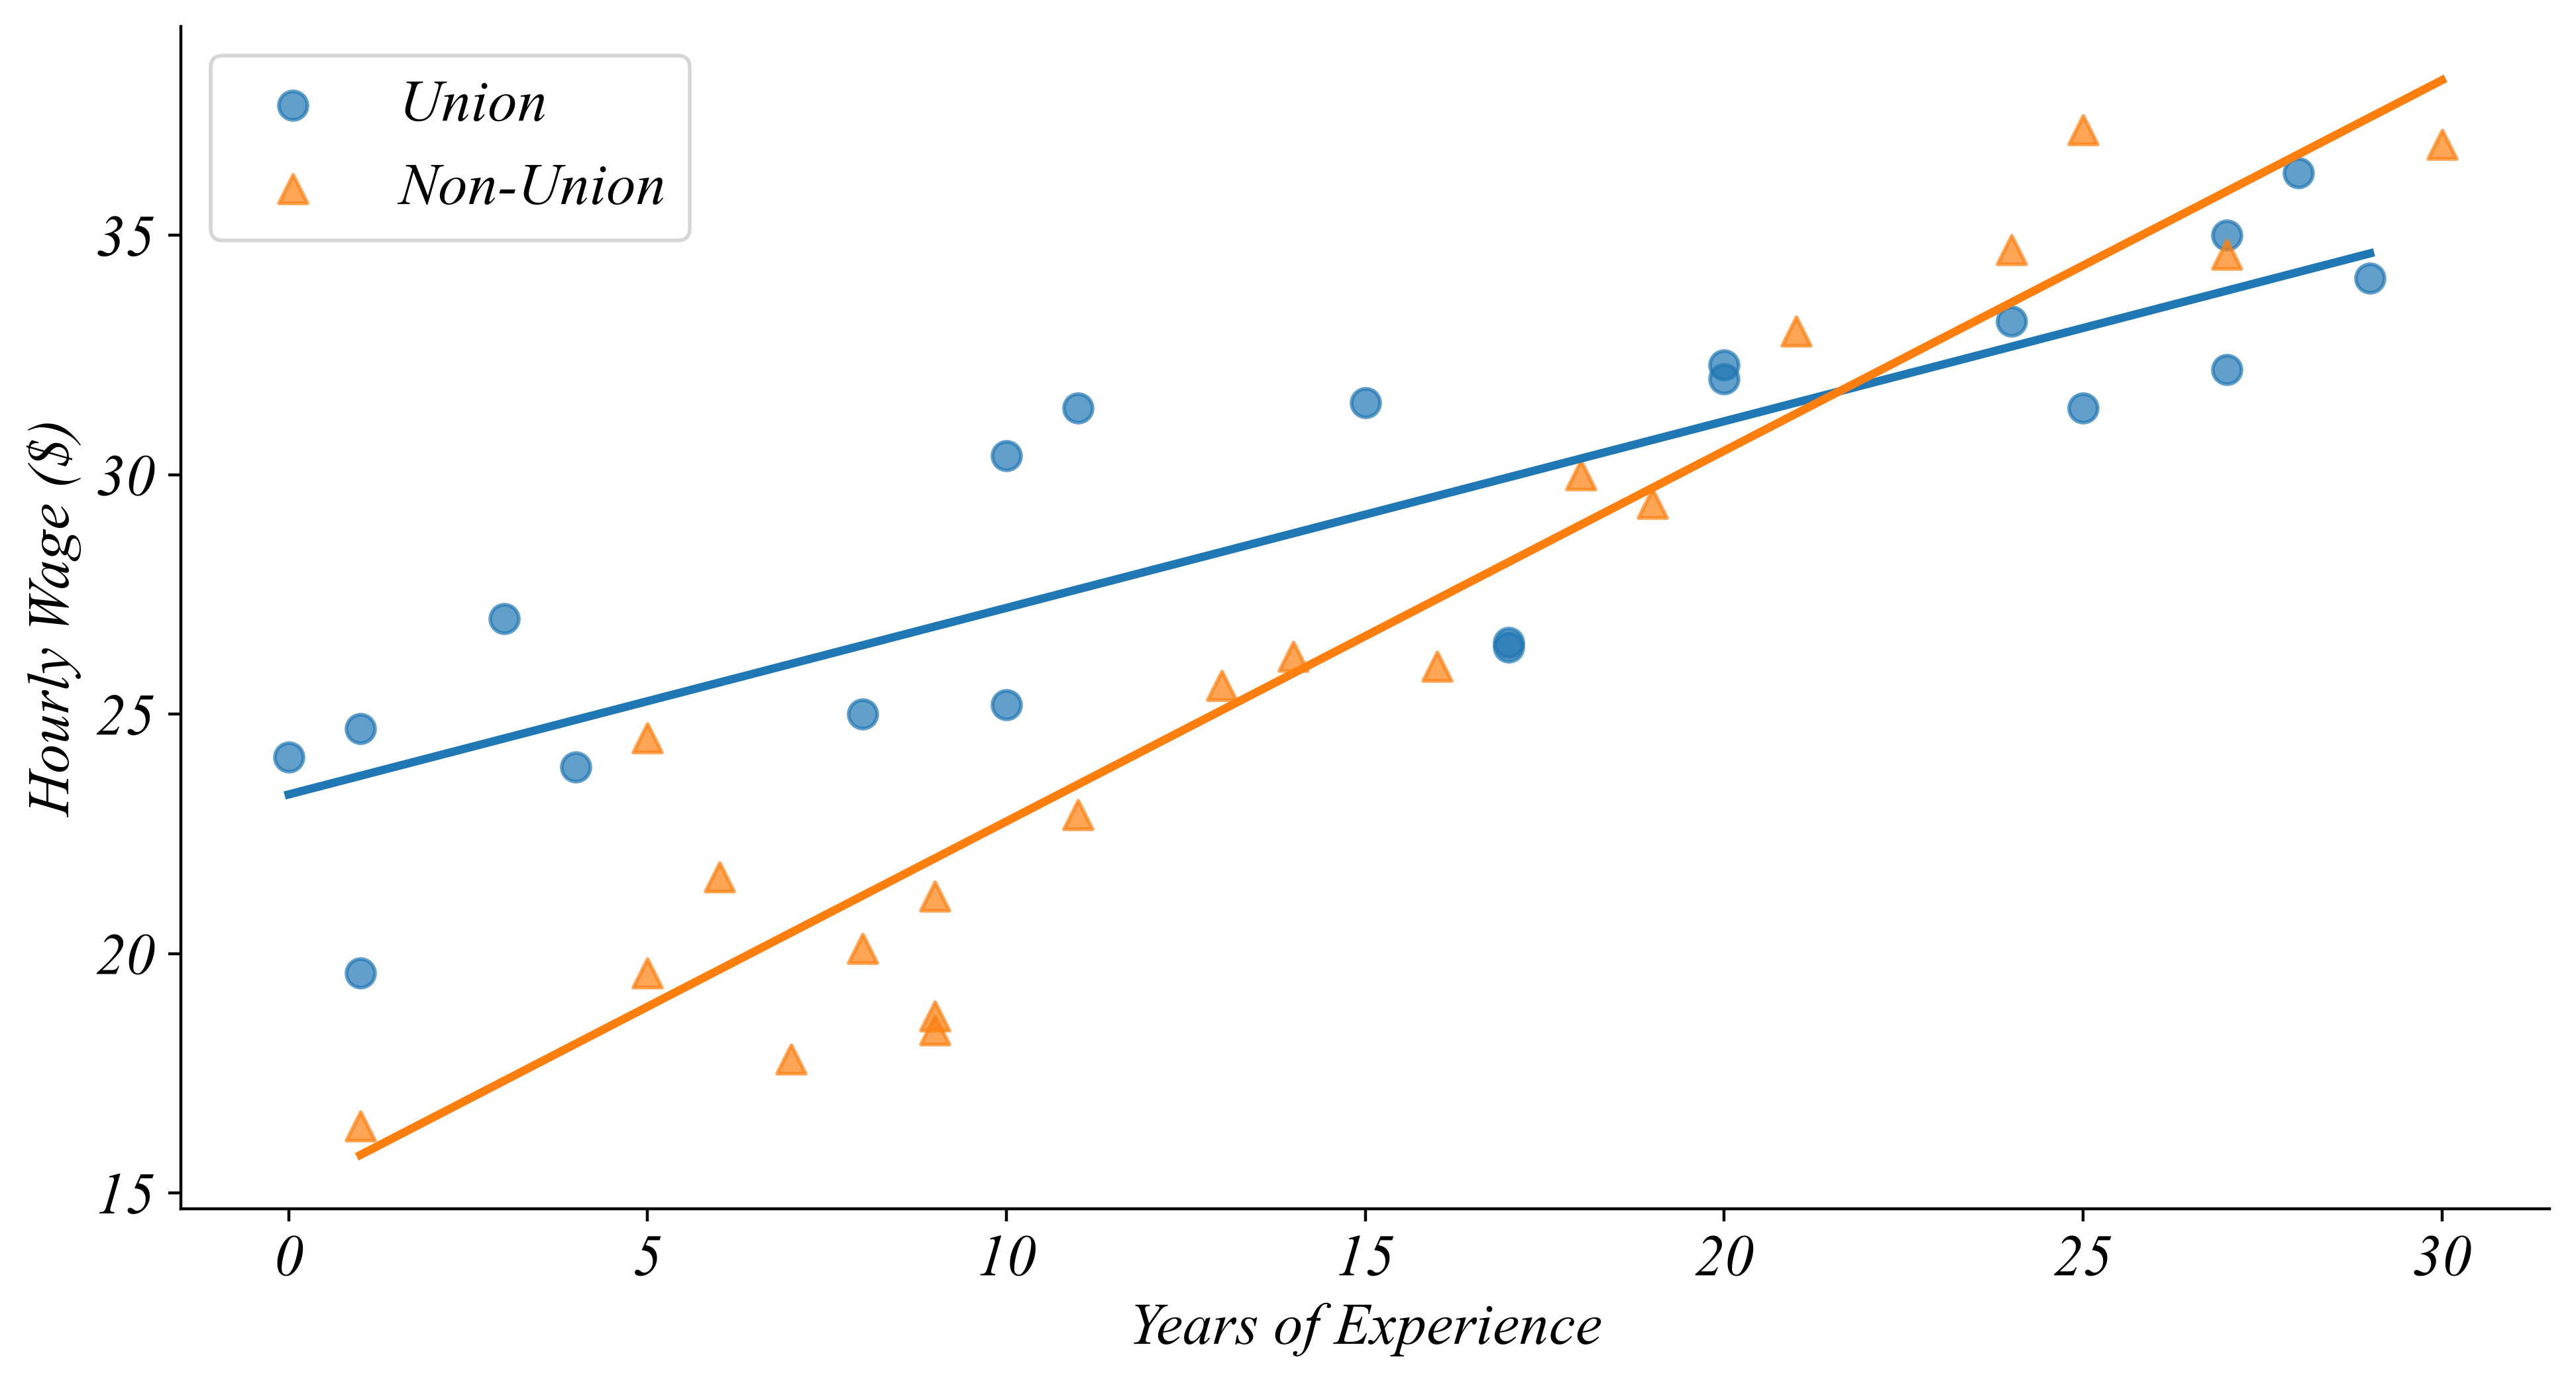

In [7]:
# Union workers start higher; non-union wages rise faster and cross near 20 years
frames = []
for grp, (b0, b1, m) in {'Union': (24, 0.35, 'o'), 'Non-Union': (15, 0.8, '^')}.items():
    x = rng.uniform(0, 30, 20).round(0)
    frames.append(pd.DataFrame({'Group': grp, 'Experience': x,
                                'Wage': (b0 + b1 * x + rng.normal(0, 2.0, 20)).round(1)}))
wages = pd.concat(frames)

fig, ax = plt.subplots(figsize=(10, 5.5))
for (grp, d), c, m in zip(wages.groupby('Group', sort=False), [C0, C1], ['o', '^']):
    sns.regplot(data=d, x='Experience', y='Wage', ci=None, color=c, marker=m, label=grp,
                scatter_kws={'s': 60, 'alpha': 0.7}, ax=ax)
ax.set(xlabel='Years of Experience', ylabel='Hourly Wage ($)')
ax.legend(); sns.despine(); plt.tight_layout(); plt.savefig('i/f26_hue_read.png'); plt.show()

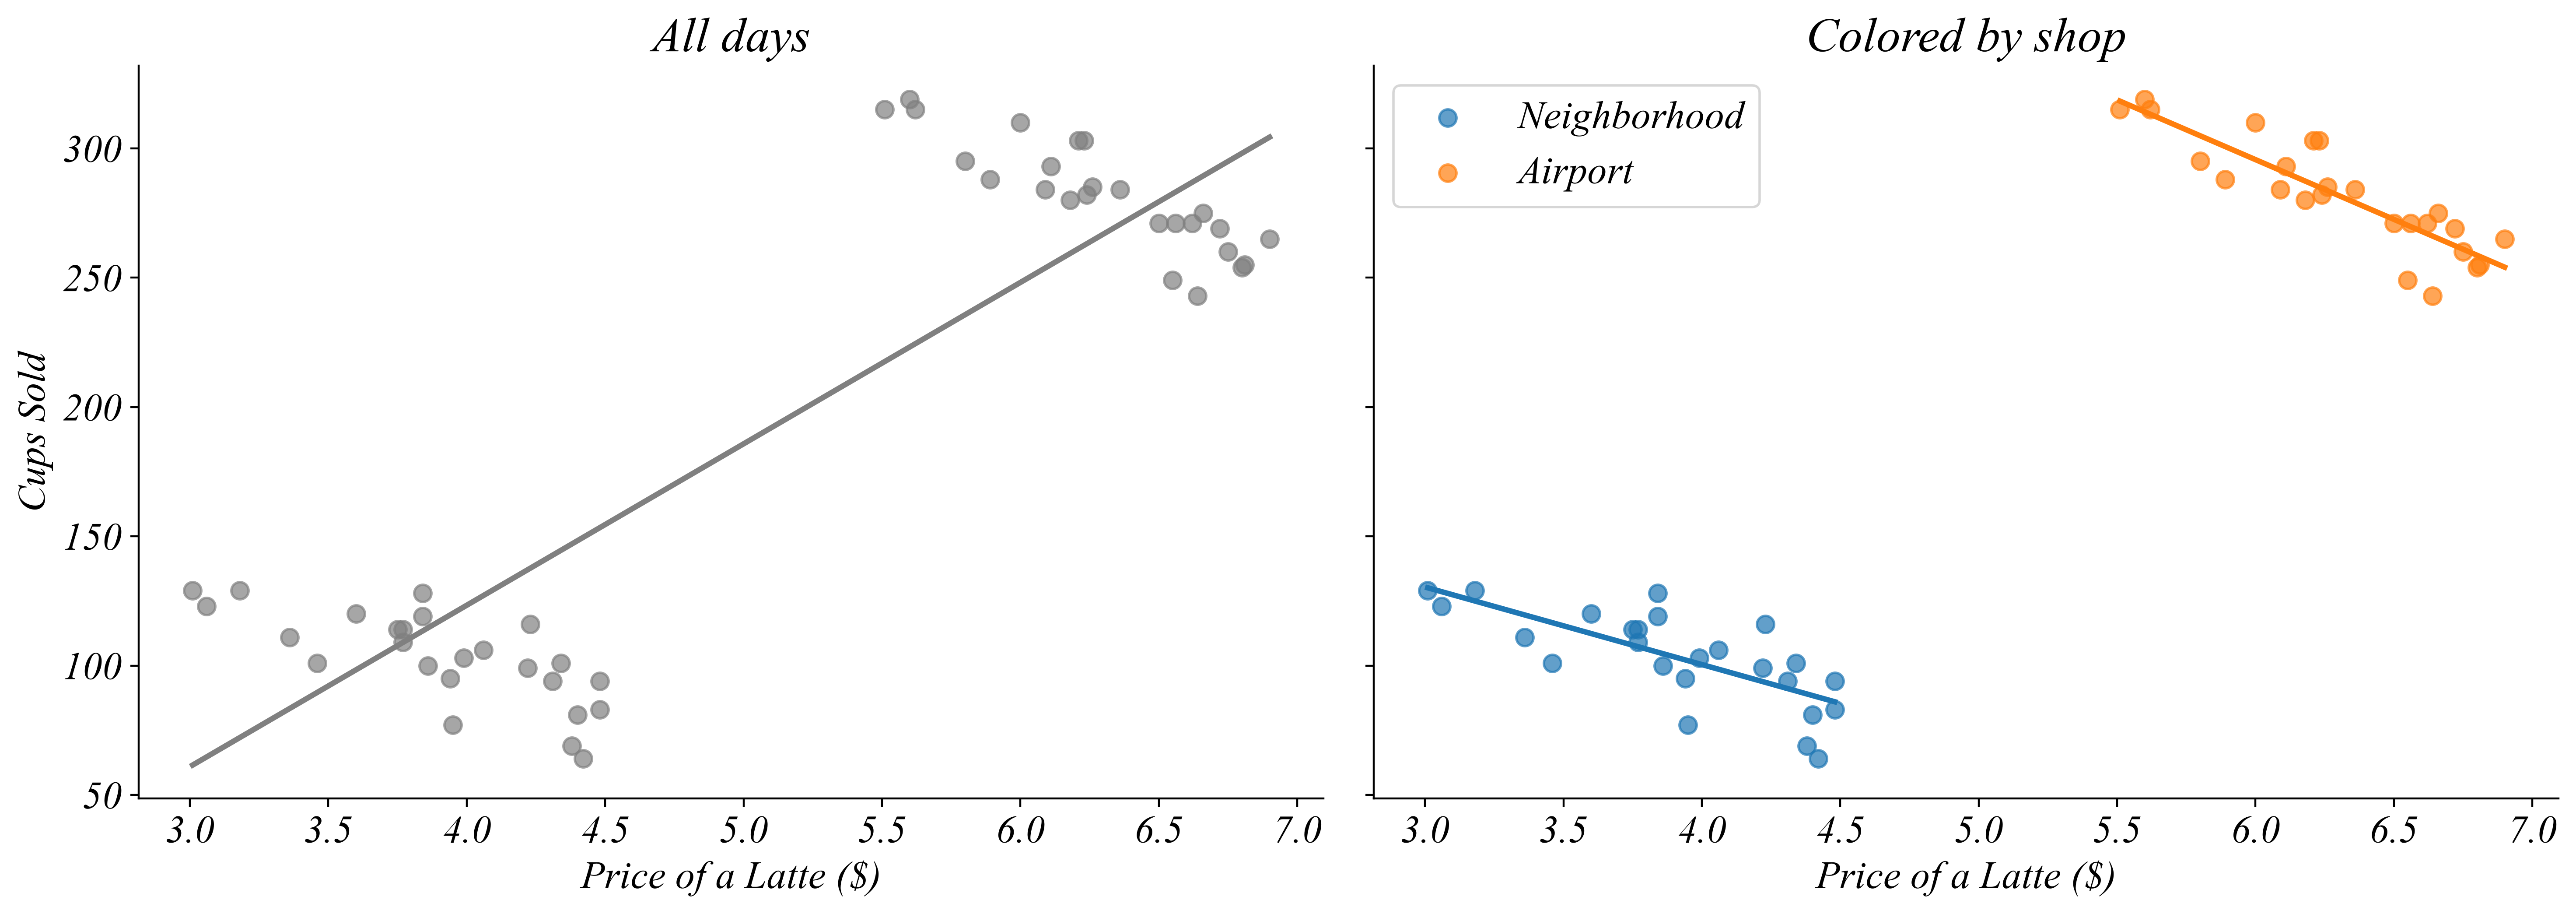

In [8]:
# Pooled vs by group: each point is one day at one coffee shop
frames = []
for shop, (lo, hi, b0, b1) in {'Neighborhood': (3.0, 4.5, 260, -40), 'Airport': (5.5, 7.0, 600, -50)}.items():
    p = rng.uniform(lo, hi, 25).round(2)
    frames.append(pd.DataFrame({'Shop': shop, 'Price': p,
                                'Cups': (b0 + b1 * p + rng.normal(0, 12, 25)).round(0)}))
cups = pd.concat(frames)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
sns.regplot(data=cups, x='Price', y='Cups', ci=None, color='gray', scatter_kws={'s': 50, 'alpha': 0.7}, ax=axes[0])
axes[0].set(title='All days', xlabel='Price of a Latte ($)', ylabel='Cups Sold')
for (shop, d), c in zip(cups.groupby('Shop', sort=False), [C0, C1]):
    sns.regplot(data=d, x='Price', y='Cups', ci=None, color=c, label=shop, scatter_kws={'s': 50, 'alpha': 0.7}, ax=axes[1])
axes[1].set(title='Colored by shop', xlabel='Price of a Latte ($)', ylabel='')
axes[1].legend(); sns.despine(); plt.tight_layout(); plt.savefig('i/f26_pooled_vs_group.png'); plt.show()

## Answer checks for the typed tables

In [9]:
# Filter -> group -> mean
txn = pd.DataFrame({
    'Txn': [f'T0{i}' for i in range(1, 9)],
    'Offer': ['BOGO 5', 'BOGO 10', 'BOGO 5', 'Discount', 'BOGO 10', 'BOGO 5', 'Discount', 'BOGO 10'],
    'Event': ['Purchase', 'Viewed', 'Purchase', 'Purchase', 'Purchase', 'Viewed', 'Purchase', 'Purchase'],
    'Amount': [12, 0, 20, 8, 30, 0, 16, 18]})
print(txn[txn['Event'] == 'Purchase'].groupby('Offer')['Amount'].agg(['mean', 'count']))
print(txn.groupby('Offer')['Amount'].mean().round(2))

# Boolean filter
apts = pd.DataFrame({
    'Apt': ['A1', 'A2', 'A3', 'A4', 'A5', 'A6'],
    'Area': ['Urban', 'Rural', 'Suburban', 'Urban', 'Suburban', 'Rural'],
    'Rent': [1850, 900, 1400, 1450, 1650, 1200],
    'Bedrooms': [1, 3, 2, 1, 3, 2]})
print(apts[apts['Area'].isin(['Urban', 'Suburban']) & (apts['Rent'] < 1500)]['Apt'].tolist())

# Merge and melt
population = pd.DataFrame({'City': ['Alder', 'Birch', 'Cedar', 'Dogwood'], 'Population': [120_000, 850_000, 2_400_000, 45_000]})
rents = pd.DataFrame({'City': ['Alder', 'Birch', 'Cedar', 'Elm'], 'Rent_2019': [950, 1300, 2000, 800], 'Rent_2024': [1150, 1600, 2300, 980]})
merged = pd.merge(population, rents, on='City')
print(merged)
print(merged.melt(id_vars=['City', 'Population'], value_vars=['Rent_2019', 'Rent_2024'], var_name='Year', value_name='Rent'))

          mean  count
Offer                
BOGO 10   24.0      2
BOGO 5    16.0      2
Discount  12.0      2
Offer
BOGO 10     16.00
BOGO 5      10.67
Discount    12.00
Name: Amount, dtype: float64
['A3', 'A4']
    City  Population  Rent_2019  Rent_2024
0  Alder      120000        950       1150
1  Birch      850000       1300       1600
2  Cedar     2400000       2000       2300
    City  Population       Year  Rent
0  Alder      120000  Rent_2019   950
1  Birch      850000  Rent_2019  1300
2  Cedar     2400000  Rent_2019  2000
3  Alder      120000  Rent_2024  1150
4  Birch      850000  Rent_2024  1600
5  Cedar     2400000  Rent_2024  2300
